# Sequence-to-Sequence (Seq2Seq) with Attention
*Inside Deep Learning (E. Raff), Chapter 11*

A Seq2Seq model maps one sequence to another sequence of a **different length**. It combines:

| Part | Role | Biology analogy |
|---|---|---|
| **Encoder** (bidirectional GRU) | Reads the whole input and produces one vector per token | Reading an entire mRNA before deciding anything |
| **Decoder** (GRUCell loop) | Generates the output one token at a time | A ribosome emitting one amino acid per step |
| **Attention** | At every output step, decides which input tokens to look at | The ribosome "looking" at the current codon, not the whole transcript |

## Machine Translation and the `DataLoader`
Download and pre-process an English → French translation corpus.

In [1]:
# ── Imports ──────────────────────────────────────────────────────────────────
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence   # FIX: was missing
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.autonotebook import tqdm
from sklearn.metrics import accuracy_score

# Import dl_utils (patched version: GPU-side argmax, no per-batch .item() sync)
import sys, os
sys.path.insert(0, os.path.abspath("../DL_utils_EZA"))
%load_ext autoreload
%autoreload 2
from dl_utils import *
print("dl_utils loaded ✅")

# ── Reproducibility ───────────────────────────────────────────────────────────
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

# ── Device setup ──────────────────────────────────────────────────────────────
# Sentences have DIFFERENT lengths in every batch. cudnn.benchmark=True would
# re-benchmark kernels for every new shape and slow training down -> keep False.
torch.backends.cudnn.benchmark = False

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device : {device}")
if device.type == 'cuda':
    props = torch.cuda.get_device_properties(0)
    # 11.35 GB (decimal, 1e9) == 10.57 GiB (binary, 2**30): same memory, two units.
    print(f"GPU    : {props.name}")
    print(f"VRAM   : {props.total_memory / 2**30:.2f} GiB")

/tmp/ipykernel_21657/2522863666.py:11: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from tqdm.autonotebook import tqdm


dl_utils loaded ✅
Device : cuda
GPU    : NVIDIA GeForce RTX 2080 Ti
VRAM   : 10.57 GiB


In [2]:
# Additional libraries for downloading the dataset
from io import BytesIO
from zipfile import ZipFile
from urllib.request import urlopen
import re

In [3]:
all_data = []
resp = urlopen("https://download.pytorch.org/tutorial/data.zip")
zipfile = ZipFile(BytesIO(resp.read()))

for line in zipfile.open("data/eng-fra.txt").readlines():
    line = line.decode("utf-8").lower()
    line = re.sub(r"[-.!?]+", r" ", line)
    source_lang, target_lang = line.split("\t")[0:2]
    all_data.append((source_lang.strip(), target_lang.strip()))

In [4]:
# Explore the dataset
for i in range(5):
    print(all_data[i])

('go', 'va')
('run', 'cours')
('run', 'courez')
('wow', 'ça alors')
('fire', 'au feu')


In [5]:
# Keep only sentence pairs with six or fewer words (faster training, easier task)
MAX_LEN = 6
short_subset = [(s, t) for (s, t) in all_data
                if max(len(s.split(" ")), len(t.split(" "))) <= MAX_LEN]

print("Using", len(short_subset), "of", len(all_data), "sentences for training.")

Using 66251 of 135842 sentences for training.


### Building the vocabulary. SOS, EOS and PAD tokens
Each unique word gets an integer ID. Three special tokens are added:

| Token | ID | Purpose |
|---|---|---|
| `<PADDING_>` | 0 | Fills shorter sentences so a batch is a rectangle. ID 0 + `padding_idx=0` makes its embedding an all-zero vector, which is how the mask finds padding. |
| `<SOS>` | 1 | Start of sentence |
| `<EOS>` | 2 | End of sentence: tells the decoder when to stop |

Note: English and French share **one** vocabulary here. This is the book's simplification; real systems use two.

In [6]:
SOS_token = "<SOS>"
EOS_token = "<EOS>"
PAD_token = "<PADDING_>"

word2idx = {PAD_token: 0, SOS_token: 1, EOS_token: 2}
for s, t in short_subset:
    for sentence in (s, t):
        for word in sentence.split(" "):
            if word not in word2idx:
                word2idx[word] = len(word2idx)

# Reverse mapping: index -> word
idx2word = {indx: word for word, indx in word2idx.items()}

# Tensor Cores (Turing, FP16) run fastest when matrix dimensions are multiples of 8.
# The output layer is Linear(hidden, vocab), the biggest matrix in the model, so we
# round the vocabulary up. The extra IDs are never used as targets.
VOCAB_SIZE = int(np.ceil(len(word2idx) / 8) * 8)
print("Vocabulary size:", len(word2idx), "-> padded to", VOCAB_SIZE)

Vocabulary size: 24577 -> padded to 24584


### Implementing a translation `Dataset`
Turns a pair of strings into a pair of `int64` tensors.
- Source: `<SOS> words <EOS>`
- Target: `words <EOS>` (no `<SOS>`: the decoder's first input is the source's `<EOS>`)

In [7]:
class TranslationDataset(Dataset):
    '''
    Takes a list of (source, target) string tuples and converts each into a
    tuple of int64 tensors. Words are split on spaces.
    '''
    def __init__(self, lang_pairs, word2idx):
        self.lang_pairs = lang_pairs
        self.word2idx = word2idx

    def __len__(self):
        return len(self.lang_pairs)

    def __getitem__(self, idx):
        x, y = self.lang_pairs[idx]
        x = SOS_token + " " + x + " " + EOS_token
        y = y + " " + EOS_token

        x = [self.word2idx[word] for word in x.split(" ")]
        y = [self.word2idx[word] for word in y.split(" ")]
        return torch.tensor(x, dtype=torch.int64), torch.tensor(y, dtype=torch.int64)

bigdataset = TranslationDataset(short_subset, word2idx)

### Collate function and DataLoaders
`pad_batch` pads every sentence in a batch to the length of the longest one.
It returns `((X, Y), Y)`: the model receives the target too (needed for teacher forcing), and `Y` is also the label for the loss.

**Hardware notes (RTX 2080 Ti on Thunderbolt 3):**
- `pin_memory=True` + `non_blocking=True` (inside `moveTo`) let CPU→GPU copies overlap with compute. This matters on an eGPU, whose link is slower than an internal PCIe slot.
- A batch of 128 sentences × ~8 tokens is only ~8 KB of integers, so the data is never the bottleneck. The bottleneck is the decoder's Python `for` loop.
- The **test** loader must not shuffle: evaluation should be deterministic.

In [8]:
BATCH_SIZE = 128
PAD = word2idx[PAD_token]

train_size = round(len(bigdataset) * 0.9)
test_size = len(bigdataset) - train_size
train_dataset, test_dataset = torch.utils.data.random_split(
    bigdataset, [train_size, test_size],
    generator=torch.Generator().manual_seed(SEED))   # reproducible split

def pad_batch(batch):
    '''Pads a batch of sequences to the length of the longest sequence.'''
    max_x = max(i[0].size(0) for i in batch)
    max_y = max(i[1].size(0) for i in batch)

    X = [F.pad(i[0], (0, max_x - i[0].size(0)), value=PAD) for i in batch]
    Y = [F.pad(i[1], (0, max_y - i[1].size(0)), value=PAD) for i in batch]
    X, Y = torch.stack(X), torch.stack(Y)
    return (X, Y), Y

loader_kwargs = dict(num_workers=4, pin_memory=True, persistent_workers=True,
                     collate_fn=pad_batch)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,  **loader_kwargs)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False, **loader_kwargs)  # FIX: no shuffle

(xb, yb), _ = next(iter(train_loader))
print("Source batch:", xb.shape, "| Target batch:", yb.shape)

Source batch: torch.Size([128, 8]) | Target batch: torch.Size([128, 7])


## Inputs to Seq2Seq
There are two options for the decoder's input at step $t$:

| Approach | Input at step $t$ | Pro | Con |
|---|---|---|---|
| **Autoregressive** | The model's own prediction from step $t-1$ | Matches how the model is used at inference | Early mistakes compound, so training is slow |
| **Teacher forcing** | The correct token $y_{t-1}$ | Fast, stable learning | The model never practices recovering from its own errors |

In both cases, the first input is the last token of the source (`<EOS>`).
*We use both: a coin flip per batch decides which.*

## Seq2Seq with attention
1. **Encode:** the bidirectional GRU turns the input into one hidden vector per token, $\boldsymbol{h}_1 \dots \boldsymbol{h}_T$.
2. **Decode:** the GRUCell stack produces a decoder state $\hat{\boldsymbol{z}}_t$ (the "query").
3. **Attend:** score each $\boldsymbol{h}_i$ against $\hat{\boldsymbol{z}}_t$, softmax the scores (padding masked out), and take the weighted average $\bar{\boldsymbol{x}}_t$.
4. **Predict:** concatenate $[\bar{\boldsymbol{x}}_t, \hat{\boldsymbol{z}}_t]$ and map it to a score for every word in the vocabulary.

### Attention helpers
These come from the book's `idlmam` module. They are defined here directly instead of `from idlmam import *`,
because that star-import also brings in the book's own `train_network`, `moveTo`, `run_epoch`, etc.,
which silently **overwrite** your `dl_utils` versions imported above.

In [9]:
def getMaskByFill(x, time_dimension=1, fill=0):
    '''
    x : (B, T, D) embedded batch -> bool mask (B, T). True = real token.
    PAD has an all-zero embedding (padding_idx=0), so a time step is padding
    exactly when every feature equals `fill`.
    '''
    to_sum_over = [d for d in range(1, x.dim()) if d != time_dimension]
    with torch.no_grad():
        mask = (x != fill)
        if to_sum_over:
            mask = mask.sum(dim=to_sum_over) > 0
    return mask


class DotScore(nn.Module):
    '''Scaled dot-product score: how well each encoder state matches the query.'''
    def __init__(self, H):
        super().__init__()
        self.H = H

    def forward(self, states, context):
        # states (B, T, H) @ context (B, H, 1) -> (B, T, 1)
        return torch.bmm(states, context.unsqueeze(2)) / np.sqrt(self.H)


class ApplyAttention(nn.Module):
    '''Softmax over time (padding masked) + weighted sum of encoder states.'''
    def forward(self, states, attention_scores, mask=None):
        if mask is not None:
            # -1e4 fits in FP16 (max 65504). -inf or -1e9 can produce NaN under AMP.
            attention_scores = attention_scores.masked_fill(~mask.unsqueeze(2), -1e4)
        weights = F.softmax(attention_scores, dim=1)     # (B, T, 1), sums to 1 over T
        final_context = (states * weights).sum(dim=1)    # (B, H)
        return final_context, weights

### Why the previous block-by-block cells failed
The original notebook wrote the body of `forward()` as separate top-level cells. Python ran them **outside the class**, which caused a chain of errors:

| Cell | Error | Root cause |
|---|---|---|
| Prep / mask | `'function' object has no attribute 'size'` | Outside a method, `input` is Python's built-in `input()` **function**, not a tensor |
| Encoding | `NameError: pack_padded_sequence` | Never imported (it lives in `torch.nn.utils.rnn`) |
| Decode prep, attention, next input | `NameError: self` / `decoder_input` | `self` only exists inside a method; each failure cascaded into the next cell |
| Return | `SyntaxError: 'return' outside function` | `return` is only legal inside a function |

Beyond those visible errors, the draft also had **silent bugs** that would not crash but would quietly ruin training:

| Silent bug | Effect | Fix |
|---|---|---|
| `pad_packed_sequence(h_encoded)` without `batch_first=True`, then `.view(B, T, -1)` | Output is `(T, B, H)`. `.view` just relabels memory, so words from **different sentences get mixed together**. Training "works" but learns garbage. | `pad_packed_sequence(..., batch_first=True, total_length=T)` |
| No `for t in range(steps)` loop | Only one output word would ever be produced | Wrap blocks 4–6 in the time loop |
| `decoder_input` never updated | Every step would see the same input | `decoder_input = self.embd(next_words)` |
| `all_predictions`, `all_attentions`, `teacher_forcing` never created | `NameError` once inside the method | Initialize them before the loop |
| `target[:, t].squeeze()` | With batch size 1 this becomes a 0-D scalar and `nn.Embedding` output loses its batch dimension | Drop `.squeeze()` |
| `multinomial(F.softmax(word_pred))` under AMP | FP16 softmax over 24k words can underflow to all-zeros → `multinomial` error | `.float()` before softmax |

The lesson: writing a method across separate cells is a nice way to *read* code, but it cannot *run*. The block structure now lives as comments inside one class.

### Implementing the Seq2Seq model
The `forward()` method contains the seven blocks you studied:

1. **Prep, embedding and mask:** unpack `(input, target)`, embed tokens, find padding
2. **Encoding:** pack → bidirectional GRU → unpack; build the decoder's initial state
3. **Decode prep:** first decoder input (`<EOS>`), number of steps, teacher-forcing coin flip
4. **Context and attention:** run the GRUCell stack, score, attend
5. **Prediction:** concatenate context + decoder state → vocabulary scores
6. **Next decoder input:** teacher forcing, sampling, or argmax
7. **Return:** predictions (train) or predictions + attention maps (eval)

In [10]:
class Seq2SeqAttention(nn.Module):
    def __init__(self, num_embeddings, embd_size, hidden_size, padding_idx=None,
                 layers=1, max_decode_length=20):
        super().__init__()
        self.padding_idx = padding_idx
        self.hidden_size = hidden_size
        self.embd = nn.Embedding(num_embeddings, embd_size, padding_idx=padding_idx)
        # Bidirectional encoder: each direction gets H/2 so the concatenation is H.
        self.encode_layers = nn.GRU(input_size=embd_size, hidden_size=hidden_size // 2,
                                    num_layers=layers, bidirectional=True, batch_first=True)
        # Unidirectional decoder from GRUCells: one time step per call.
        self.decode_layers = nn.ModuleList(
            [nn.GRUCell(embd_size, hidden_size)] +
            [nn.GRUCell(hidden_size, hidden_size) for _ in range(layers - 1)])
        self.score_net = DotScore(hidden_size)
        # Maps [attention result, decoder state] -> a score for every word.
        self.predict_word = nn.Sequential(
            nn.Linear(2 * hidden_size, hidden_size), nn.LeakyReLU(), nn.LayerNorm(hidden_size),
            nn.Linear(hidden_size, hidden_size),     nn.LeakyReLU(), nn.LayerNorm(hidden_size),
            nn.Linear(hidden_size, num_embeddings))
        self.max_decode_length = max_decode_length
        self.apply_attn = ApplyAttention()

    def forward(self, input):
        # ── 1. PREP, EMBEDDING AND MASK ──────────────────────────────────────
        if isinstance(input, (tuple, list)):
            input, target = input
        else:
            target = None
        B, T = input.size(0), input.size(1)
        x = self.embd(input)                                   # (B, T, E)
        mask = getMaskByFill(x)                                # (B, T) bool
        seq_lengths = mask.sum(dim=1).view(-1)                 # (B,) real lengths

        # ── 2. ENCODING ──────────────────────────────────────────────────────
        # Packing lets the GRU skip padding entirely (no wasted compute,
        # and the final hidden state is taken at each sentence's true end).
        x_packed = pack_padded_sequence(x, seq_lengths.cpu(), batch_first=True,
                                        enforce_sorted=False)
        h_encoded, h_last = self.encode_layers(x_packed)
        h_encoded, _ = pad_packed_sequence(h_encoded, batch_first=True, total_length=T)
        hidden_size = h_encoded.size(2)                        # (B, T, H)
        # h_last: (layers*2, B, H/2) -> last layer, both directions -> (B, H)
        h_last = h_last.view(-1, 2, B, hidden_size // 2)[-1, :, :, :]
        h_last = h_last.permute(1, 0, 2).reshape(B, -1)

        # ── 3. DECODE PREP ───────────────────────────────────────────────────
        h_prevs = [h_last for _ in range(len(self.decode_layers))]
        last_idx = (seq_lengths - 1).view(-1, 1)               # position of <EOS>
        decoder_input = self.embd(input.gather(1, last_idx).flatten())   # (B, E)
        steps = min(self.max_decode_length, T)
        if target is not None:
            steps = target.size(1)
        teacher_forcing = bool(np.random.rand() < 0.5)         # coin flip per batch

        all_attentions, all_predictions = [], []
        for t in range(steps):
            # ── 4. CONTEXT AND ATTENTION ─────────────────────────────────────
            x_in = decoder_input
            for l in range(len(self.decode_layers)):
                h = self.decode_layers[l](x_in, h_prevs[l])
                h_prevs[l] = h
                x_in = h
            h_decoder = x_in                                   # (B, H) the "query"
            scores = self.score_net(h_encoded, h_decoder)      # (B, T, 1)
            context, weights = self.apply_attn(h_encoded, scores, mask=mask)
            all_attentions.append(weights.detach())

            # ── 5. PREDICTION ────────────────────────────────────────────────
            word_pred = self.predict_word(torch.cat((context, h_decoder), dim=1))  # (B, V)
            all_predictions.append(word_pred)

            # ── 6. NEXT DECODER INPUT ────────────────────────────────────────
            if self.training:
                if target is not None and teacher_forcing:
                    next_words = target[:, t]                  # correct previous word
                else:
                    probs = F.softmax(word_pred.detach().float(), dim=1)
                    next_words = torch.multinomial(probs, 1)[:, -1]   # sample
            else:
                next_words = torch.argmax(word_pred, dim=1)    # most likely word
            decoder_input = self.embd(next_words)

        # ── 7. RETURN ────────────────────────────────────────────────────────
        preds = torch.stack(all_predictions, dim=1)            # (B, steps, V)
        if self.training:
            return preds
        attn = torch.stack(all_attentions, dim=1).squeeze(-1)  # (B, steps, T)
        return preds, attn

### Shape sanity check (before any training)
A habit worth keeping: push one small batch through the untrained model and **assert** the shapes and properties you expect. It takes seconds and catches most wiring bugs.

In [11]:
_m = Seq2SeqAttention(VOCAB_SIZE, 64, 128, padding_idx=PAD, layers=2).to(device)
(xb, yb), _ = next(iter(test_loader))
xb, yb = xb[:8].to(device), yb[:8].to(device)

_m.train()
out = _m((xb, yb))
assert out.shape == (8, yb.size(1), VOCAB_SIZE), out.shape

_m.eval()
with torch.no_grad():
    out, attn = _m((xb, yb))
assert attn.shape == (8, yb.size(1), xb.size(1))
assert torch.allclose(attn.sum(-1), torch.ones_like(attn.sum(-1)), atol=1e-4)   # rows sum to 1
pad_positions = (xb == PAD).unsqueeze(1).expand_as(attn)
assert attn[pad_positions].max().item() < 1e-3 if pad_positions.any() else True # no attention on PAD
print("All shape checks passed ✅", out.shape, attn.shape)
del _m, out, attn

All shape checks passed ✅ torch.Size([8, 7, 24584]) torch.Size([8, 7, 8])


### Loss function
`nn.CrossEntropyLoss` expects `(N, C)` logits and `(N,)` labels, but our model outputs `(B, T, V)`.
We flatten batch and time together and set `ignore_index=PAD` so padded positions add nothing to the loss.
In eval mode the model returns `(predictions, attention)`, so the loss keeps only the first element.

In [12]:
class CrossEntLossTime(nn.Module):
    '''Cross-entropy over (B, T, V) sequence logits, ignoring PAD targets.'''
    def __init__(self, ignore_index=0):
        super().__init__()
        self.cel = nn.CrossEntropyLoss(ignore_index=ignore_index)

    def forward(self, x, y):
        if isinstance(x, tuple):          # eval mode: (logits, attention)
            x = x[0]
        T = min(x.size(1), y.size(1))
        x, y = x[:, :T, :], y[:, :T]
        return self.cel(x.reshape(-1, x.size(-1)), y.reshape(-1))

### Training and evaluation
Configuration from the book: embedding 64, hidden 256, 2 layers, 20 epochs.

| Setting | Value | Why |
|---|---|---|
| `use_amp=True` | FP16 autocast + GradScaler | ~half the activation memory, Tensor Core speed-up on Turing |
| `ignore_index=PAD` | passed to `train_network_EZA` | Accuracy is computed per **real token**, not counting padding |
| `score_funcs` | token accuracy | Safe now: the patched `run_epoch` takes `argmax` on the GPU, so only 1 integer per token is copied to RAM instead of 24,584 floats |
| Optimizer | AdamW, lr 1e-3 | Default from `train_network_EZA` |

**Memory estimate:** the largest tensor is the output logits, `B × T × V` = 128 × 7 × 24,584 ≈ 22M values ≈ 44 MB in FP16, plus its gradient and the per-step activations. Expect well under 2 GiB of VRAM; the GPU will be under-utilized because the decoder loop runs one step at a time in Python. That is a property of RNN decoders, not a problem with your setup.

In [13]:
EPOCHS = 20
os.makedirs("./checkpoints", exist_ok=True)

seq2seq = Seq2SeqAttention(VOCAB_SIZE, embd_size=64, hidden_size=256,
                           padding_idx=PAD, layers=2, max_decode_length=MAX_LEN + 2)

if device.type == 'cuda':
    torch.cuda.reset_peak_memory_stats()

seq_results = train_network_EZA(
    seq2seq, CrossEntLossTime(ignore_index=PAD), train_loader,
    test_loader=test_loader,
    score_funcs={'Accuracy': accuracy_score},
    epochs=EPOCHS, device=device,
    checkpoint_file="./checkpoints/seq2seq_attention.tar",
    use_amp=True, ignore_index=PAD)

if device.type == 'cuda':
    print(f"Peak VRAM: {torch.cuda.max_memory_allocated() / 2**30:.2f} GiB")

Epoch: 100%|██████████| 20/20 [04:41<00:00, 14.10s/it]


Peak VRAM: 0.40 GiB


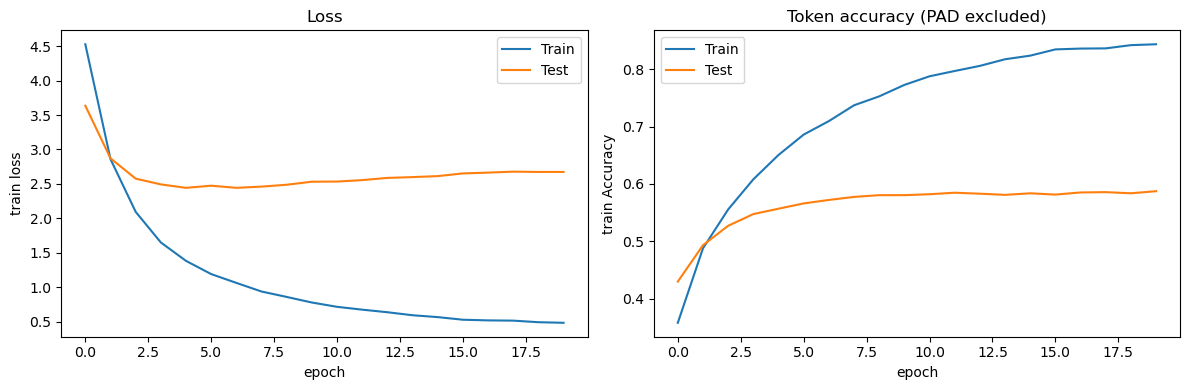

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.lineplot(x='epoch', y='train loss', data=seq_results, label='Train', ax=axes[0])
sns.lineplot(x='epoch', y='test loss',  data=seq_results, label='Test',  ax=axes[0])
axes[0].set_title("Loss")
sns.lineplot(x='epoch', y='train Accuracy', data=seq_results, label='Train', ax=axes[1])
sns.lineplot(x='epoch', y='test Accuracy',  data=seq_results, label='Test',  ax=axes[1])
axes[1].set_title("Token accuracy (PAD excluded)")
plt.tight_layout(); plt.show()

### Translating new sentences and visualizing attention
At inference there is no target, so the model decodes for `min(max_decode_length, T)` steps where `T` is the source length.
French is often longer than English, so we append PAD tokens to the source to give the decoder room. The mask makes these extra PADs invisible to attention.

EN: some animals are afraid of fire
FR: certains animaux ont peur du feu


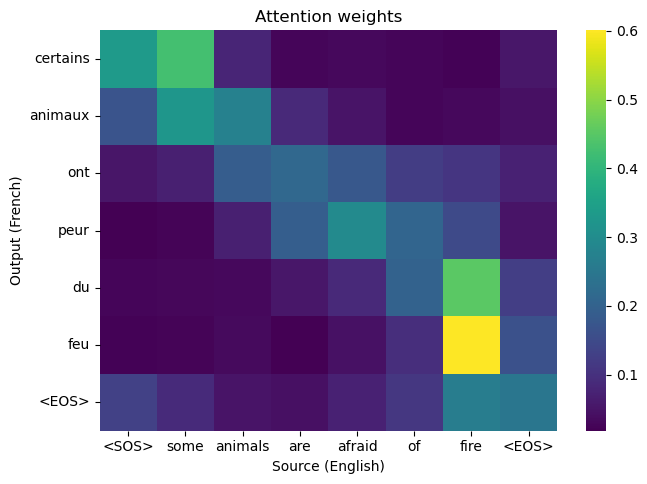

EN: what is the weather like today
FR: quel temps fait il aujourd'hui


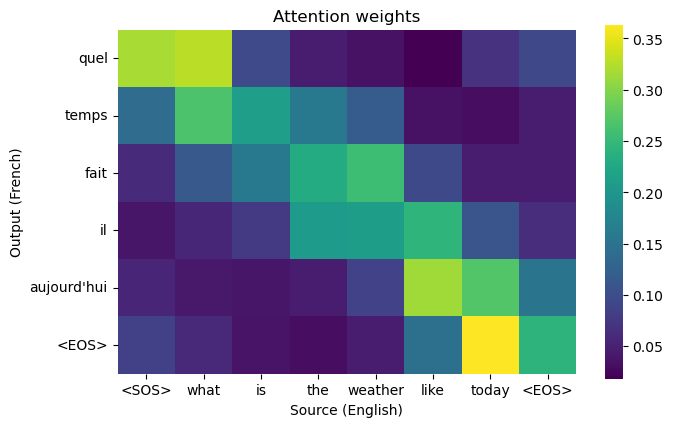

EN: no one disagreed
FR: personne n'exprima de désaccord


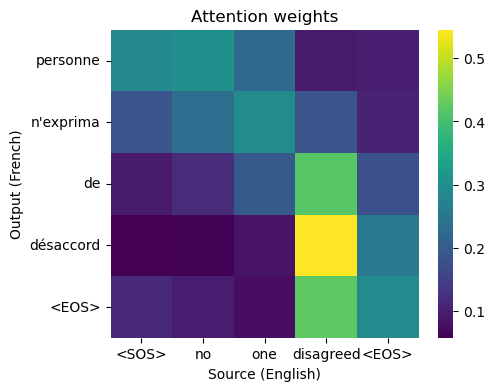

In [25]:
def translate(sentence, model, max_len=MAX_LEN + 2, plot=True):
    model.eval()
    words = sentence.lower().strip().split(" ")
    unknown = [w for w in words if w not in word2idx]
    if unknown:
        print(f"Skipping words not in vocabulary: {unknown}")
    words = [w for w in words if w in word2idx]
    src = [SOS_token] + words + [EOS_token]
    ids = [word2idx[w] for w in src]
    ids += [PAD] * max(0, max_len - len(ids))              # room for longer outputs
    x = torch.tensor(ids, dtype=torch.int64, device=device).unsqueeze(0)

    with torch.no_grad():
        logits, attn = model(x)
    pred_ids = logits.argmax(-1)[0].tolist()
    out = []
    for i in pred_ids:
        if i == word2idx[EOS_token]:
            break
        out.append(idx2word.get(i, "?"))

    print(f"EN: {sentence}\nFR: {' '.join(out)}")
    if plot:
        a = attn[0, :len(out) + 1, :len(src)].float().cpu().numpy()
        plt.figure(figsize=(len(src) * 0.8 + 1, (len(out) + 1) * 0.6 + 1))
        sns.heatmap(a, xticklabels=src, yticklabels=out + [EOS_token],
                    cmap="viridis", cbar=True, square=True)
        plt.xlabel("Source (English)"); plt.ylabel("Output (French)")
        plt.title("Attention weights"); plt.show()
    return " ".join(out)

for s in ["some animals are afraid of fire", "what is the weather like today", 
          "no one disagreed"]:
    translate(s, seq2seq)

**How to read the heatmap:** each row is one generated French word; each column is an English input word.
A bright cell means "while writing this French word, the model looked mostly at that English word".
A well-trained model shows a near-diagonal pattern, with deviations where word order differs between the languages.

## Bio Application
- Bio connection: the same encoder–attention–decoder pattern underlies protein language models and sequence-to-function models; attention maps are often inspected the same way you would inspect a contact map.